In [ ]:
from pathlib import Path
import subprocess
import hashlib
import zipfile

project = Path("/content/roseau-scale")
project.mkdir(parents=True, exist_ok=True)

archive = project / "RCS_Dataset-v1.0.1.zip"
url = (
    "https://zenodo.org/records/22100485/files/"
    "iglabprecision/RCS_Dataset-v1.0.1.zip?download=1"
)

subprocess.run(
    ["wget", "-c", "--progress=dot:giga", "-O", str(archive), url],
    check=True
)

digest = hashlib.md5()
with archive.open("rb") as file:
    for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
        digest.update(chunk)

actual = digest.hexdigest()
print("MD5:", actual)
assert actual == "511d470b5889e52dcb1958dab6323ece", (
    "Checksum mismatch. Stop before extracting."
)

with zipfile.ZipFile(archive) as z:
    files = [entry for entry in z.infolist() if not entry.is_dir()]
    print("Files:", len(files))
    print("Uncompressed GB:", round(
        sum(entry.file_size for entry in files) / 1024**3, 2
    ))

    print("\nFirst 25 filenames:")
    for entry in files[:25]:
        print(entry.filename)

    print("\nNotebooks, settings, metadata, weights, and documentation:")
    for entry in files:
        name = entry.filename
        lower = name.lower()
        if (
            lower.endswith((".ipynb", ".yaml", ".yml", ".csv", ".pt", ".py"))
            or "license" in lower
            or "readme" in lower
        ):
            print(name)

MD5: 511d470b5889e52dcb19*******
Files: 3756
Uncompressed GB: 1.11

First 25 filenames:
iglabprecision-RCS_Dataset-dbad16a/README.md
iglabprecision-RCS_Dataset-dbad16a/code/notebooktraintesting2.ipynb
iglabprecision-RCS_Dataset-dbad16a/code/tiled.pt
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6976.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6977.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6979.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6980.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6981.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6982.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6983.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6984.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSCN6985.jpg
iglabprecision-RCS_Dataset-dbad16a/datasets/downsampled/images/DSC

In [ ]:
import json
import zipfile
from collections import Counter
from pathlib import PurePosixPath

with zipfile.ZipFile(archive) as z:
    names = [n for n in z.namelist() if not n.endswith("/")]
    root = names[0].split("/")[0]

    print("=== README ===")
    print(z.read(f"{root}/README.md").decode("utf-8-sig"))

    print("\n=== NOTEBOOK CODE CELLS ===")
    notebook = json.loads(
        z.read(f"{root}/code/notebooktraintesting2.ipynb")
    )
    for i, cell in enumerate(notebook["cells"]):
        if cell["cell_type"] == "code":
            print(f"\n--- Cell {i} ---")
            print("".join(cell["source"]))

    print("\n=== FILE COUNTS BY FOLDER ===")
    counts = Counter(
        str(PurePosixPath(n).parent.relative_to(root))
        for n in names
    )
    for folder, count in sorted(counts.items()):
        print(f"{folder}: {count}")

    print("\n=== SAMPLE TILE FILENAMES ===")
    tiles = [
        n for n in names
        if "/tiled/" in n.lower()
        and n.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    for name in tiles[:12]:
        print(name)

    print("\n=== METADATA PREVIEW ===")
    metadata = z.read(
        f"{root}/metadata/sample_locations.csv"
    ).decode("utf-8-sig")
    print("\n".join(metadata.splitlines()[:8]))

    print("\n=== LICENSE FILES ===")
    licenses = [
        n for n in names
        if "license" in PurePosixPath(n).name.lower()
        or "copying" in PurePosixPath(n).name.lower()
    ]
    print("\n".join(licenses) or "No separate license file found.")

=== README ===
# RCS_Dataset
An image dataset consisting of high-resolution RGB images, stored in JPEG format, of internodes of roseau cane (_Phragmites australis_ (Cav.) Trin. Ex Steud. (Poales: Poaceae) infested by varying numbers of roseau cane scale (_Nipponaclerda biwakoensis_ Kuwana (Hemiptera: Aclerdidae)), intended for use in object detection. Associated bounding box coordinates can be found for each dataset in their respective _labels_ folder, presented in standard YOLO format. Each image in the _original_ and _downsampled_ datasets depicts all infested portions of separate cane stalks collected from various sites across the Mississippi River Delta, whose coordinates are available in the _metadata_ folder.
##
[![DOI](https://zenodo.org/badge/1170964830.svg)](https://doi.org/10.5281/zenodo.21300589)


=== NOTEBOOK CODE CELLS ===

--- Cell 1 ---
!nvidia-smi

--- Cell 2 ---
import torch
torch.cuda.is_available()

#get gpu details
if torch.cuda.is_available():
    print("GPU Name:

In [ ]:
import csv
import io
import re
import zipfile
from collections import Counter
from pathlib import PurePosixPath

with zipfile.ZipFile(archive) as z:
    names = [n for n in z.namelist() if not n.endswith("/")]
    root = names[0].split("/")[0]

    originals = {
        PurePosixPath(n).stem
        for n in names
        if "/datasets/original/images/" in n
    }

    tiles = [
        n for n in names
        if "/datasets/tiled/images/" in n
    ]

    parent_counts = Counter()
    unmatched = []

    for name in tiles:
        match = re.match(r"^(DSCN\d+)_", PurePosixPath(name).name)
        if match and match.group(1) in originals:
            parent_counts[match.group(1)] += 1
        else:
            unmatched.append(name)

    rows = list(csv.DictReader(io.StringIO(
        z.read(f"{root}/metadata/sample_locations.csv")
        .decode("utf-8-sig")
    )))

    metadata_ids = [PurePosixPath(r["filename"]).stem for r in rows]
    sites = Counter(r["SITE"] for r in rows)

    print("Original images:", len(originals))
    print("Tiles:", len(tiles))
    print("Originals represented by tiles:", len(parent_counts))
    print("Unmatched tiles:", len(unmatched))
    print("Originals without tiles:", len(originals - set(parent_counts)))
    print("Metadata rows:", len(rows))
    print("Duplicate metadata filenames:",
          len(metadata_ids) - len(set(metadata_ids)))
    print("Originals missing metadata:",
          len(originals - set(metadata_ids)))
    print("Sampling sites:", len(sites))

    print("\nImages per site:")
    for site, count in sorted(sites.items()):
        print(site, count)

    if unmatched:
        print("\nUnmatched examples:", unmatched[:5])

Original images: 265
Tiles: 1346
Originals represented by tiles: 263
Unmatched tiles: 0
Originals without tiles: 2
Metadata rows: 265
Duplicate metadata filenames: 0
Originals missing metadata: 0
Sampling sites: 28

Images per site:
AN 1 6
AN 2 12
AN 3 10
AN 4 10
AN 5.1 10
AN 6 10
AN 7 10
JC 1.1 7
JC 2.1 10
JC 3.2 10
JC 4 11
JC 5.1 11
JC 6 11
JC 7 10
JC 8.2 9
LM1 10
LM3 9
LM4 9
LM5 9
LM6 10
RD 10.1 9
RD 11 10
RD 12 10
RD 13 10
RD 14 11
RD 15 10
RD 16 10
RD10.1 1


In [ ]:
import csv
import io
import zipfile
from pathlib import PurePosixPath

with zipfile.ZipFile(archive) as z:
    names = set(z.namelist())
    root = next(n for n in names if n.endswith("/README.md")).split("/")[0]

    rows = list(csv.DictReader(io.StringIO(
        z.read(f"{root}/metadata/sample_locations.csv")
        .decode("utf-8-sig")
    )))
    by_id = {
        PurePosixPath(row["filename"]).stem: row
        for row in rows
    }

    print("=== POSSIBLE SITE-NAME VARIANT ===")
    for row in rows:
        if row["SITE"].replace(" ", "").upper() == "RD10.1":
            print(row)

    print("\n=== ORIGINALS WITHOUT TILES ===")
    for image_id in sorted(originals - set(parent_counts)):
        row = by_id[image_id]
        print("\nMetadata:", row)

        for variant in ("original", "downsampled"):
            label = (
                f"{root}/datasets/{variant}/labels/{image_id}.txt"
            )
            if label not in names:
                print(variant, "LABEL FILE MISSING")
                continue

            lines = [
                line for line in z.read(label).decode().splitlines()
                if line.strip()
            ]
            print(variant, "bounding boxes:", len(lines))

=== POSSIBLE SITE-NAME VARIANT ===
{'filename': 'DSCN7093.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7096.jpg', 'SITE': 'RD10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7099.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7225.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7228.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7232.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7233.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7236.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7239.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude': '-89.36678'}
{'filename': 'DSCN7242.jpg', 'SITE': 'RD 10.1', 'Latitude': '28.99924', 'Longitude':

In [ ]:
import csv
import io
import json
import random
import hashlib
import zipfile
from pathlib import Path

SEED = 42
output = Path("/content/roseau-scale/experiment")
output.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive) as z:
    rows = list(csv.DictReader(io.StringIO(
        z.read(f"{root}/metadata/sample_locations.csv")
        .decode("utf-8-sig")
    )))

manifest = []
for row in rows:
    record = dict(row)
    record["site_raw"] = row["SITE"]
    record["site_group"] = (
        "RD 10.1" if row["SITE"] == "RD10.1" else row["SITE"]
    )
    manifest.append(record)

sites = sorted({r["site_group"] for r in manifest})
assert len(sites) == 27

random.Random(SEED).shuffle(sites)
groups = {
    "train": set(sites[:21]),
    "val": set(sites[21:24]),
    "test": set(sites[24:])
}

assert not (groups["train"] & groups["val"])
assert not (groups["train"] & groups["test"])
assert not (groups["val"] & groups["test"])

for row in manifest:
    row["split"] = next(
        split for split, members in groups.items()
        if row["site_group"] in members
    )

manifest.sort(key=lambda r: r["filename"])
path = output / "split_manifest.csv"

buffer = io.StringIO(newline="")
writer = csv.DictWriter(buffer, fieldnames=list(manifest[0]))
writer.writeheader()
writer.writerows(manifest)
content = buffer.getvalue()

if path.exists() and path.read_text() != content:
    raise RuntimeError("Existing manifest differs; it was not overwritten.")
path.write_text(content)

config = {
    "seed": SEED,
    "grouping": "normalized sampling site",
    "site_counts": {"train": 21, "val": 3, "test": 3},
    "normalization": {"RD10.1": "RD 10.1"},
    "archive_md5": "511d470b5889e52dcb1958dab6323ece",
    "note": "Independent split; not the authors' original split."
}
(output / "split_config.json").write_text(json.dumps(config, indent=2))

for split, members in groups.items():
    count = sum(r["split"] == split for r in manifest)
    print(f"{split}: {len(members)} sites, {count} original images")
    print("Sites:", ", ".join(sorted(members)))

print("\nManifest SHA256:",
      hashlib.sha256(path.read_bytes()).hexdigest())
print("Saved:", path)

train: 21 sites, 212 original images
Sites: AN 2, AN 3, AN 5.1, AN 6, AN 7, JC 3.2, JC 4, JC 5.1, JC 6, JC 7, JC 8.2, LM1, LM3, LM4, LM5, LM6, RD 11, RD 12, RD 14, RD 15, RD 16
val: 3 sites, 27 original images
Sites: JC 1.1, JC 2.1, RD 13
test: 3 sites, 26 original images
Sites: AN 1, AN 4, RD 10.1

Manifest SHA256: e1db9a0548f30244ef4292d8b597a17c16942465e95a25fb21460673c0b1f213
Saved: /content/roseau-scale/experiment/split_manifest.csv


In [ ]:
from pathlib import Path
from collections import Counter
import zipfile
import math

base = Path("/content/roseau-scale")

with zipfile.ZipFile(archive) as z:
    # Ensure every member stays inside the extraction directory.
    for member in z.infolist():
        destination = (base / member.filename).resolve()
        if base.resolve() not in destination.parents:
            raise ValueError(f"Unexpected archive path: {member.filename}")
    z.extractall(base)

dataset_root = base / root
issues = []
summary = {}

for variant in ("original", "downsampled", "tiled"):
    folder = dataset_root / "datasets" / variant
    images = {
        p.stem: p for p in (folder / "images").iterdir()
        if p.suffix.lower() in (".jpg", ".jpeg", ".png")
    }
    labels = {p.stem: p for p in (folder / "labels").glob("*.txt")}

    boxes = 0
    empty = 0

    for stem in sorted(images.keys() - labels.keys()):
        issues.append(f"{variant}: missing label for {stem}")
    for stem in sorted(labels.keys() - images.keys()):
        issues.append(f"{variant}: label without image: {stem}")

    for stem, label in sorted(labels.items()):
        lines = [s for s in label.read_text().splitlines() if s.strip()]
        empty += not lines

        for line_number, line in enumerate(lines, 1):
            try:
                values = [float(v) for v in line.split()]
                assert len(values) == 5
                cls, x, y, w, h = values
                assert all(math.isfinite(v) for v in values)
                assert cls == 0
                assert 0 <= x <= 1 and 0 <= y <= 1
                assert 0 < w <= 1 and 0 < h <= 1
                # Allow small rounding differences at image boundaries.
                assert x - w/2 >= -1e-4 and x + w/2 <= 1.0001
                assert y - h/2 >= -1e-4 and y + h/2 <= 1.0001
                boxes += 1
            except (ValueError, AssertionError):
                issues.append(
                    f"{variant}/{label.name}:{line_number}: {line}"
                )

    summary[variant] = {
        "images": len(images),
        "labels": len(labels),
        "valid_boxes": boxes,
        "empty_labels": empty,
    }

for variant, counts in summary.items():
    print(variant, counts)

print("\nAnnotation issues:", len(issues))
for issue in issues[:20]:
    print(issue)

import json
audit = base / "experiment" / "annotation_audit.json"
audit.write_text(json.dumps(
    {"summary": summary, "issues": issues}, indent=2
))
print("\nSaved:", audit)

original {'images': 265, 'labels': 265, 'valid_boxes': 12410, 'empty_labels': 2}
downsampled {'images': 265, 'labels': 265, 'valid_boxes': 12410, 'empty_labels': 2}
tiled {'images': 1346, 'labels': 1346, 'valid_boxes': 13295, 'empty_labels': 64}

Annotation issues: 16
tiled/DSCN7005_JPG.rf.19263c300db2b3966cec39561d991c9e.txt:24: 0 0.19661458333333334 0 0.021701388888888888 0
tiled/DSCN7040_JPG.rf.f2e78b668e8e69febf0c426d5091f63a.txt:2: 0 0 0.6558159722222222 0 0.1293402777777778
tiled/DSCN7063_JPG.rf.acc69b5bf9441ae75161bfd9332190ed.txt:1: 0 0.5746527777777778 0 0.050347222222222224 0
tiled/DSCN7092_JPG.rf.e3316ae007b7acbc5d72eb8fb817cb59.txt:7: 0 0.6336805555555556 0 0.07118055555555555 0
tiled/DSCN7095_JPG.rf.141506dc903b20e895f01714f5967a68.txt:2: 0 0 0.5 0 0.050347222222222224
tiled/DSCN7104_JPG.rf.6f9d9da28920dd627b8ebfd3e69c18e9.txt:54: 0 0 0.65234375 0 0.042534722222222224
tiled/DSCN7121_JPG.rf.bee054a9e5f54b8bbbf01ab59790cfc2.txt:25: 0 0.8368055555555556 0 0.029513888888888888

In [ ]:
import csv
import json
import re
import shutil
from pathlib import Path
from collections import Counter

base = Path("/content/roseau-scale")
source = dataset_root / "datasets" / "tiled"
prepared = base / "prepared" / "tiled"

with (base / "experiment/split_manifest.csv").open() as f:
    manifest = list(csv.DictReader(f))

split_by_parent = {
    Path(row["filename"]).stem: row["split"]
    for row in manifest
}

# Check all labels before writing any derived data.
records = []
removed = []

for image in sorted((source / "images").glob("*.jpg")):
    match = re.match(r"^(DSCN\d+)_", image.name)
    assert match, image.name
    parent = match.group(1)
    split = split_by_parent[parent]
    label = source / "labels" / f"{image.stem}.txt"
    kept = []

    for number, line in enumerate(label.read_text().splitlines(), 1):
        if not line.strip():
            continue

        values = [float(v) for v in line.split()]
        assert len(values) == 5, (label.name, number)
        cls, x, y, w, h = values

        if w == 0 or h == 0:
            removed.append({
                "file": label.name,
                "line": number,
                "text": line,
                "split": split,
                "reason": "zero-area bounding box"
            })
        else:
            assert w > 0 and h > 0
            kept.append(line)

    records.append((image, split, kept))

assert len(records) == 1346
assert len(removed) == 16

counts = Counter()
boxes = Counter()
empty = Counter()

for image, split, kept in records:
    image_dir = prepared / "images" / split
    label_dir = prepared / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(image, image_dir / image.name)
    (label_dir / f"{image.stem}.txt").write_text(
        "\n".join(kept) + ("\n" if kept else "")
    )
    counts[split] += 1
    boxes[split] += len(kept)
    empty[split] += not kept

yaml_path = prepared / "data.yaml"
yaml_path.write_text(
    f"path: {prepared}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "names:\n"
    "  0: scale\n"
)

report = {
    "policy": "Remove zero-area boxes only; retain all tiles.",
    "source_labels_modified": False,
    "removed": removed,
    "images": dict(counts),
    "boxes": dict(boxes),
    "empty_labels": dict(empty),
}
(base / "experiment/label_cleaning.json").write_text(
    json.dumps(report, indent=2)
)

for split in ("train", "val", "test"):
    print(
        f"{split}: {counts[split]} tiles, "
        f"{boxes[split]} boxes, {empty[split]} empty labels"
    )

print("Removed boxes:", len(removed))
print("YOLO config:", yaml_path)

train: 1044 tiles, 9915 boxes, 56 empty labels
val: 179 tiles, 2153 boxes, 4 empty labels
test: 123 tiles, 1227 boxes, 4 empty labels
Removed boxes: 16
YOLO config: /content/roseau-scale/prepared/tiled/data.yaml


In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

backup = Path("/content/drive/MyDrive/roseau-scale-robustness")
backup.mkdir(parents=True, exist_ok=True)

# Preserve the frozen split and audit records.
shutil.copytree(
    "/content/roseau-scale/experiment",
    backup / "experiment",
    dirs_exist_ok=True
)

# Pack prepared data for faster restoration.
packed = shutil.make_archive(
    "/content/roseau-scale/prepared_tiled",
    "zip",
    root_dir="/content/roseau-scale/prepared"
)
shutil.copy2(packed, backup / "prepared_tiled.zip")

# Keep the verified source archive for full-image evaluation later.
source_archive = Path("/content/roseau-scale/RCS_Dataset-v1.0.1.zip")
saved_archive = backup / source_archive.name

if not saved_archive.exists():
    shutil.copy2(source_archive, saved_archive)

for path in sorted(backup.iterdir()):
    print(path.name,
          f"{path.stat().st_size / 1024**2:.1f} MB"
          if path.is_file() else "(folder)")

print("\nBackup complete:", backup)

Mounted at /content/drive
RCS_Dataset-v1.0.1.zip 1130.6 MB
experiment (folder)
prepared_tiled.zip 160.0 MB

Backup complete: /content/drive/MyDrive/roseau-scale-robustness


In [ ]:
!nvidia-smi


Mon Oct 19 19:31:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: False


In [ ]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())


PyTorch: 2.11.0+cpu
CUDA build: None
GPU available: False


In [ ]:
import os
import shutil

print("Colab GPU setting:", os.environ.get("COLAB_GPU"))
print("NVIDIA utility:", shutil.which("nvidia-smi"))

Colab GPU setting: 1
NVIDIA utility: /opt/bin/nvidia-smi


In [ ]:
from google.colab import drive
from pathlib import Path
import torch
import zipfile
import shutil
import hashlib

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Stop here: PyTorch cannot use the GPU."
print("GPU:", torch.cuda.get_device_name(0))

drive.mount("/content/drive")

backup = Path("/content/drive/MyDrive/roseau-scale-robustness")
base = Path("/content/roseau-scale")
base.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    backup / "experiment",
    base / "experiment",
    dirs_exist_ok=True
)

local_zip = base / "prepared_tiled.zip"
shutil.copy2(backup / "prepared_tiled.zip", local_zip)

with zipfile.ZipFile(local_zip) as z:
    z.extractall(base / "prepared")

manifest = base / "experiment/split_manifest.csv"
checksum = hashlib.sha256(manifest.read_bytes()).hexdigest()
assert checksum == (
    "e1db9a0548f30244ef4292d8b597a17c169"
    "42465e95a25fb21460673c0b1f213"
), "Split manifest changed."

data = base / "prepared/tiled"
expected = {"train": 1044, "val": 179, "test": 123}

for split, count in expected.items():
    images = list((data / "images" / split).glob("*.jpg"))
    labels = list((data / "labels" / split).glob("*.txt"))
    assert len(images) == len(labels) == count
    print(f"{split}: {len(images)} images, {len(labels)} labels")

print("Frozen split verified.")
print("Dataset restored:", data)

PyTorch: 2.11.0+cu130
CUDA build: 13.0
GPU available: True
GPU: Tesla T4
Mounted at /content/drive
train: 1044 images, 1044 labels
val: 179 images, 179 labels
test: 123 images, 123 labels
Frozen split verified.
Dataset restored: /content/roseau-scale/prepared/tiled


In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.0 MB/s eta 0:00:00


In [ ]:
import sys
import json
import subprocess
from pathlib import Path

import torch
import torchvision
import ultralytics

assert torch.cuda.is_available(), "GPU is no longer available."

experiment = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/experiment"
)
experiment.mkdir(parents=True, exist_ok=True)

environment = {
    "python": sys.version,
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "ultralytics": ultralytics.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
}

(experiment / "environment.json").write_text(
    json.dumps(environment, indent=2)
)

packages = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"], text=True
)
(experiment / "requirements-frozen.txt").write_text(packages)

print(json.dumps(environment, indent=2))
print("\nEnvironment saved to Drive.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "ultralytics": "8.4.182",
  "cuda": "13.0",
  "gpu": "Tesla T4"
}

Environment saved to Drive.


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import json
import shutil

data_yaml = Path("/content/roseau-scale/prepared/tiled/data.yaml")
assert data_yaml.exists()

run_root = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/runs"
)
run_name = "smoke_yolov8n_seed42"

assert not (run_root / run_name).exists(), (
    "This run already exists. Inspect it before rerunning."
)

# Standard pretrained initialization, not the authors' tiled.pt.
model = YOLO("yolov8n.pt")

results = model.train(
    data=str(data_yaml),
    epochs=2,
    imgsz=512,
    batch=16,
    device=0,
    workers=2,
    optimizer="AdamW",
    lr0=0.002,
    momentum=0.937,
    seed=42,
    deterministic=True,
    amp=True,
    cache=False,
    close_mosaic=0,
    project=str(run_root),
    name=run_name,
    save=True,
    plots=True,
)

run_dir = Path(model.trainer.save_dir)
print("\nRun saved:", run_dir)
print("Best checkpoint:", (run_dir / "weights/best.pt").exists())
print("Last checkpoint:", (run_dir / "weights/last.pt").exists())

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roseau-scale/prepared/tiled/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_yolov8n_seed42, nbs=64, nms=None, ops

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch

assert torch.cuda.is_available()

run_root = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/runs"
)
run_name = "baseline_tiled_seed42_50epochs"

assert not (run_root / run_name).exists(), (
    "Run already exists. Stop to avoid overwriting or duplicating it."
)

model = YOLO("yolov8n.pt")

model.train(
    data="/content/roseau-scale/prepared/tiled/data.yaml",
    epochs=50,
    imgsz=512,
    batch=16,
    device=0,
    workers=2,
    optimizer="AdamW",
    lr0=0.002,
    momentum=0.937,
    seed=42,
    deterministic=True,
    amp=True,
    cache=False,
    patience=100,       # Allow the full 50-epoch schedule.
    close_mosaic=10,
    project=str(run_root),
    name=run_name,
    save=True,
    save_period=10,
    plots=True,
)

print("\nCompleted:", model.trainer.save_dir)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roseau-scale/prepared/tiled/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_tiled_seed42_50epochs, nbs=64, n

In [ ]:
from pathlib import Path
import csv
import zipfile
import shutil

backup = Path("/content/drive/MyDrive/roseau-scale-robustness")
base = Path("/content/roseau-scale")
local_archive = base / "RCS_Dataset-v1.0.1.zip"

if not local_archive.exists():
    shutil.copy2(backup / local_archive.name, local_archive)

with (base / "experiment/split_manifest.csv").open() as f:
    validation = [
        row for row in csv.DictReader(f)
        if row["split"] == "val"
    ]

destination = base / "evaluation/full_val"
for folder in ("images", "labels"):
    (destination / folder).mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(local_archive) as z:
    root = next(
        n.split("/")[0] for n in z.namelist()
        if n.endswith("/README.md")
    )

    for row in validation:
        filename = row["filename"]
        for folder, name in (
            ("images", filename),
            ("labels", Path(filename).stem + ".txt")
        ):
            member = f"{root}/datasets/downsampled/{folder}/{name}"
            (destination / folder / name).write_bytes(z.read(member))

counts = []
for label in sorted((destination / "labels").glob("*.txt")):
    counts.append(sum(
        bool(line.strip()) for line in label.read_text().splitlines()
    ))

assert len(counts) == 27
print("Validation full images:", len(counts))
print("Annotated insects:", sum(counts))
print("Insects per image: min =", min(counts), "max =", max(counts))
print("Saved:", destination)

Validation full images: 27
Annotated insects: 2001
Insects per image: min = 12 max = 207
Saved: /content/roseau-scale/evaluation/full_val


In [ ]:
from pathlib import Path
import json
import cv2
import numpy as np
import torch
from torchvision.ops import nms
from ultralytics import YOLO

checkpoint = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/runs/"
    "baseline_tiled_seed42_50epochs/weights/best.pt"
)
folder = Path("/content/roseau-scale/evaluation/full_val")
out = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/experiment"
)
model = YOLO(str(checkpoint))

TILE = 512
STRIDE = 384
NMS_IOU = 0.5
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

def starts(length):
    return sorted(set(
        list(range(0, max(length - TILE, 0) + 1, STRIDE))
        + [max(length - TILE, 0)]
    ))

def predict(image):
    result = model.predict(
        image, imgsz=512, conf=0.05, iou=NMS_IOU,
        max_det=1000, device=0, verbose=False
    )[0]
    return (
        result.boxes.xyxy.cpu(),
        result.boxes.conf.cpu()
    )

records = []

for index, path in enumerate(sorted((folder / "images").glob("*.jpg"))):
    image = cv2.imread(str(path))
    assert image is not None, path
    height, width = image.shape[:2]

    label = folder / "labels" / f"{path.stem}.txt"
    truth = sum(bool(line.strip()) for line in label.read_text().splitlines())

    full_boxes, full_scores = predict(image)

    tile_boxes, tile_scores = [], []
    for y in starts(height):
        for x in starts(width):
            boxes, scores = predict(image[y:y+TILE, x:x+TILE])
            boxes += torch.tensor([x, y, x, y])
            tile_boxes.append(boxes)
            tile_scores.append(scores)

    boxes = torch.cat(tile_boxes)
    scores = torch.cat(tile_scores)
    keep = nms(boxes, scores, NMS_IOU)

    records.append({
        "image": path.name,
        "ground_truth_count": truth,
        "full": {
            "boxes": full_boxes.tolist(),
            "scores": full_scores.tolist()
        },
        "tiled": {
            "boxes": boxes[keep].tolist(),
            "scores": scores[keep].tolist()
        }
    })
    print(f"{index + 1}/27 processed: {path.name}")

payload = {
    "checkpoint": str(checkpoint),
    "tile_size": TILE,
    "stride": STRIDE,
    "nms_iou": NMS_IOU,
    "prediction_confidence_floor": 0.05,
    "records": records
}
(out / "validation_full_predictions.json").write_text(
    json.dumps(payload)
)

print("\nMethod | Confidence | Count MAE | Bias (predicted - true)")
for method in ("full", "tiled"):
    for threshold in thresholds:
        errors = [
            sum(score >= threshold for score in r[method]["scores"])
            - r["ground_truth_count"]
            for r in records
        ]
        print(
            f"{method:6} | {threshold:.2f} | "
            f"{np.mean(np.abs(errors)):.2f} | {np.mean(errors):+.2f}"
        )

print("\nPredictions saved to Drive.")

1/27 processed: DSCN7019.jpg
2/27 processed: DSCN7020.jpg
3/27 processed: DSCN7021.jpg
4/27 processed: DSCN7023.jpg
5/27 processed: DSCN7025.jpg
6/27 processed: DSCN7027.jpg
7/27 processed: DSCN7029.jpg
8/27 processed: DSCN7031.jpg
9/27 processed: DSCN7032.jpg
10/27 processed: DSCN7034.jpg
11/27 processed: DSCN7100.jpg
12/27 processed: DSCN7101.jpg
13/27 processed: DSCN7102.jpg
14/27 processed: DSCN7103.jpg
15/27 processed: DSCN7104.jpg
16/27 processed: DSCN7116.jpg
17/27 processed: DSCN7117.jpg
18/27 processed: DSCN7201.jpg
19/27 processed: DSCN7202.jpg
20/27 processed: DSCN7203.jpg
21/27 processed: DSCN7204.jpg
22/27 processed: DSCN7205.jpg
23/27 processed: DSCN7206.jpg
24/27 processed: DSCN7207.jpg
25/27 processed: DSCN7208.jpg
26/27 processed: DSCN7209.jpg
27/27 processed: DSCN7210.jpg

Method | Confidence | Count MAE | Bias (predicted - true)
full   | 0.10 | 35.67 | -31.22
full   | 0.20 | 47.81 | -47.44
full   | 0.30 | 55.52 | -55.52
full   | 0.40 | 61.44 | -61.44
full   | 0.50 | 

In [ ]:
import json
import csv
import cv2
import torch
from pathlib import Path
from torchvision.ops import box_iou

out = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/experiment"
)
folder = Path("/content/roseau-scale/evaluation/full_val")
payload = json.loads(
    (out / "validation_full_predictions.json").read_text()
)
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

def ground_truth(record):
    image = cv2.imread(str(folder / "images" / record["image"]))
    height, width = image.shape[:2]
    label = folder / "labels" / (
        Path(record["image"]).stem + ".txt"
    )
    boxes = []
    for line in label.read_text().splitlines():
        if not line.strip():
            continue
        _, x, y, w, h = map(float, line.split())
        boxes.append([
            (x - w/2) * width, (y - h/2) * height,
            (x + w/2) * width, (y + h/2) * height
        ])
    return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)

truths = [ground_truth(r) for r in payload["records"]]
summary = []

for method in ("full", "tiled"):
    for threshold in thresholds:
        tp = fp = fn = 0

        for record, gt in zip(payload["records"], truths):
            boxes = torch.tensor(
                record[method]["boxes"], dtype=torch.float32
            ).reshape(-1, 4)
            scores = torch.tensor(record[method]["scores"])
            selected = torch.where(scores >= threshold)[0]
            selected = selected[
                torch.argsort(scores[selected], descending=True)
            ]

            overlaps = box_iou(boxes[selected], gt)
            matched = set()
            hits = 0

            # Confidence-ordered, one-to-one matching at IoU >= 0.5.
            for row in overlaps:
                candidates = [
                    j for j in range(len(gt))
                    if j not in matched and row[j].item() >= 0.5
                ]
                if candidates:
                    best = max(candidates, key=lambda j: row[j].item())
                    matched.add(best)
                    hits += 1

            tp += hits
            fp += len(selected) - hits
            fn += len(gt) - hits

        precision = tp / max(tp + fp, 1)
        recall = tp / max(tp + fn, 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-12)

        summary.append({
            "method": method, "confidence": threshold,
            "TP": tp, "FP": fp, "FN": fn,
            "precision": precision, "recall": recall, "F1": f1
        })

with (out / "validation_detection_thresholds.csv").open(
    "w", newline=""
) as f:
    writer = csv.DictWriter(f, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)

print("Method | Conf | Precision | Recall | F1 | TP / FP / FN")
for row in summary:
    print(
        f"{row['method']:6} | {row['confidence']:.2f} | "
        f"{row['precision']:.3f} | {row['recall']:.3f} | "
        f"{row['F1']:.3f} | "
        f"{row['TP']} / {row['FP']} / {row['FN']}"
    )

Method | Conf | Precision | Recall | F1 | TP / FP / FN
full   | 0.10 | 0.310 | 0.179 | 0.227 | 359 / 799 / 1642
full   | 0.20 | 0.446 | 0.160 | 0.236 | 321 / 399 / 1680
full   | 0.30 | 0.576 | 0.144 | 0.231 | 289 / 213 / 1712
full   | 0.40 | 0.696 | 0.119 | 0.203 | 238 / 104 / 1763
full   | 0.50 | 0.833 | 0.092 | 0.166 | 185 / 37 / 1816
tiled  | 0.10 | 0.536 | 0.658 | 0.591 | 1317 / 1141 / 684
tiled  | 0.20 | 0.671 | 0.604 | 0.636 | 1208 / 592 / 793
tiled  | 0.30 | 0.760 | 0.563 | 0.647 | 1126 / 355 / 875
tiled  | 0.40 | 0.822 | 0.514 | 0.632 | 1028 / 223 / 973
tiled  | 0.50 | 0.864 | 0.451 | 0.593 | 903 / 142 / 1098


In [ ]:
import json
import hashlib
from pathlib import Path

experiment = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/experiment"
)
checkpoint = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/runs/"
    "baseline_tiled_seed42_50epochs/weights/best.pt"
)

protocol = {
    "model": "YOLOv8n, tile-trained, seed 42, 50 epochs",
    "checkpoint_sha256": hashlib.sha256(
        checkpoint.read_bytes()
    ).hexdigest(),
    "split_manifest_sha256":
        "e1db9a0548f30244ef4292d8b597a17c169"
        "42465e95a25fb21460673c0b1f213",
    "input": "Downsampled full images at native dimensions",
    "inference_imgsz": 512,
    "tile_size": 512,
    "tile_stride": 384,
    "nms_iou": 0.5,
    "matching_iou": 0.5,
    "max_det_per_prediction": 1000,
    "threshold_grid": [0.1, 0.2, 0.3, 0.4, 0.5],
    "counting_comparison": {
        "selection": "Lowest clean-validation count MAE per method",
        "full_confidence": 0.1,
        "tiled_confidence": 0.2
    },
    "detection_comparison": {
        "selection": "Highest clean-validation F1 per method",
        "full_confidence": 0.2,
        "tiled_confidence": 0.3
    },
    "stress_conditions": {
        "clean": {},
        "blur_mild": {"kernel": 5, "sigma": 1.0},
        "blur_strong": {"kernel": 9, "sigma": 2.0},
        "jpeg_mild": {"quality": 70},
        "jpeg_strong": {"quality": 30},
        "dark_mild": {"pixel_multiplier": 0.75},
        "dark_strong": {"pixel_multiplier": 0.5}
    },
    "stress_policy":
        "Apply each condition separately to the decoded full image "
        "before tiling; retain dimensions and ground-truth boxes.",
    "evaluation_policy":
        "Report clean and degraded count MAE, signed bias, and "
        "micro precision/recall/F1. Keep thresholds fixed.",
    "limitations": [
        "Synthetic degradation is not field validation.",
        "One training seed and three held-out test sites.",
        "No completely uninfested originals in validation or test.",
        "Full-image inference uses the tile-trained model."
    ]
}

path = experiment / "evaluation_protocol.json"
text = json.dumps(protocol, indent=2)

if path.exists() and path.read_text() != text:
    raise RuntimeError("Existing protocol differs; not overwritten.")

path.write_text(text)
print("Protocol saved:", path)
print("Checkpoint SHA256:", protocol["checkpoint_sha256"])

Protocol saved: /content/drive/MyDrive/roseau-scale-robustness/experiment/evaluation_protocol.json
Checkpoint SHA256: 184c61f8f5bbad24b80d6a148258503ef10f51057be28f5ceed341d706e15889


In [ ]:
from pathlib import Path
import csv
import json
import hashlib
import zipfile
import cv2
import numpy as np
import torch
from torchvision.ops import nms, box_iou
from ultralytics import YOLO

base = Path("/content/roseau-scale")
backup = Path("/content/drive/MyDrive/roseau-scale-robustness")
experiment = backup / "experiment"
protocol = json.loads((experiment / "evaluation_protocol.json").read_text())

checkpoint = backup / "runs/baseline_tiled_seed42_50epochs/weights/best.pt"
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == \
    protocol["checkpoint_sha256"]

manifest_path = experiment / "split_manifest.csv"
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == \
    protocol["split_manifest_sha256"]

with manifest_path.open() as f:
    test_rows = [r for r in csv.DictReader(f) if r["split"] == "test"]
assert len(test_rows) == 26

folder = base / "evaluation/full_test"
with zipfile.ZipFile(base / "RCS_Dataset-v1.0.1.zip") as z:
    root = next(n.split("/")[0] for n in z.namelist()
                if n.endswith("/README.md"))
    for row in test_rows:
        for sub, name in (
            ("images", row["filename"]),
            ("labels", Path(row["filename"]).stem + ".txt")
        ):
            target = folder / sub / name
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(
                z.read(f"{root}/datasets/downsampled/{sub}/{name}")
            )

model = YOLO(str(checkpoint))
results_dir = experiment / "heldout_evaluation"
results_dir.mkdir(exist_ok=True)

def positions(length):
    return sorted(set(
        range(0, max(length - 512, 0) + 1, 384)
    ) | {max(length - 512, 0)})

def infer(image):
    result = model.predict(
        image, imgsz=512, conf=0.05, iou=0.5,
        max_det=1000, device=0, verbose=False
    )[0]
    return result.boxes.xyxy.cpu(), result.boxes.conf.cpu()

def degrade(image, condition, settings):
    if condition == "clean":
        return image
    if condition.startswith("blur"):
        k = settings["kernel"]
        return cv2.GaussianBlur(image, (k, k), settings["sigma"])
    if condition.startswith("jpeg"):
        ok, encoded = cv2.imencode(
            ".jpg", image,
            [cv2.IMWRITE_JPEG_QUALITY, settings["quality"]]
        )
        assert ok
        return cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    return np.clip(
        image.astype(np.float32) * settings["pixel_multiplier"], 0, 255
    ).astype(np.uint8)

def match_counts(boxes, scores, gt, threshold):
    indices = torch.where(scores >= threshold)[0]
    indices = indices[torch.argsort(scores[indices], descending=True)]
    overlaps = box_iou(boxes[indices], gt)
    matched = set()
    tp = 0
    for values in overlaps:
        candidates = [
            j for j in range(len(gt))
            if j not in matched and values[j].item() >= 0.5
        ]
        if candidates:
            matched.add(max(candidates, key=lambda j: values[j].item()))
            tp += 1
    return tp, len(indices) - tp, len(gt) - tp, len(indices)

all_metrics = []

for condition, settings in protocol["stress_conditions"].items():
    saved = results_dir / f"{condition}_predictions.json"

    if saved.exists():
        records = json.loads(saved.read_text())
        assert len(records) == 26
        print("Reusing:", condition)
    else:
        records = []
        for row in sorted(test_rows, key=lambda r: r["filename"]):
            image = cv2.imread(str(folder / "images" / row["filename"]))
            assert image is not None
            h, w = image.shape[:2]
            gt = []
            label = folder / "labels" / (Path(row["filename"]).stem + ".txt")
            for line in label.read_text().splitlines():
                if line.strip():
                    _, x, y, bw, bh = map(float, line.split())
                    gt.append([(x-bw/2)*w, (y-bh/2)*h,
                               (x+bw/2)*w, (y+bh/2)*h])

            image = degrade(image, condition, settings)
            full_boxes, full_scores = infer(image)
            boxes_list, scores_list = [], []

            for y in positions(h):
                for x in positions(w):
                    boxes, scores = infer(image[y:y+512, x:x+512])
                    boxes += torch.tensor([x, y, x, y])
                    boxes_list.append(boxes)
                    scores_list.append(scores)

            boxes = torch.cat(boxes_list)
            scores = torch.cat(scores_list)
            keep = nms(boxes, scores, 0.5)
            records.append({
                "image": row["filename"], "site": row["site_group"],
                "ground_truth_boxes": gt,
                "full": {"boxes": full_boxes.tolist(),
                         "scores": full_scores.tolist()},
                "tiled": {"boxes": boxes[keep].tolist(),
                          "scores": scores[keep].tolist()}
            })

        saved.write_text(json.dumps(records))
        print("Saved:", condition)

    for purpose in ("counting", "detection"):
        for method in ("full", "tiled"):
            threshold = protocol[f"{purpose}_comparison"][
                f"{method}_confidence"
            ]
            totals = np.zeros(3, dtype=int)
            errors = []

            for record in records:
                gt = torch.tensor(
                    record["ground_truth_boxes"], dtype=torch.float32
                ).reshape(-1, 4)
                boxes = torch.tensor(
                    record[method]["boxes"], dtype=torch.float32
                ).reshape(-1, 4)
                scores = torch.tensor(record[method]["scores"])
                tp, fp, fn, count = match_counts(boxes, scores, gt, threshold)
                totals += [tp, fp, fn]
                errors.append(count - len(gt))

                all_metrics.append({
                    "condition": condition, "purpose": purpose,
                    "method": method, "confidence": threshold,
                    "image": record["image"], "site": record["site"],
                    "true_count": len(gt), "predicted_count": count,
                    "error": count-len(gt), "TP": tp, "FP": fp, "FN": fn
                })

            tp, fp, fn = totals
            precision = tp / max(tp + fp, 1)
            recall = tp / max(tp + fn, 1)
            f1 = 2*precision*recall / max(precision+recall, 1e-12)
            print(
                f"{condition:12} {purpose:9} {method:5} "
                f"MAE={np.mean(np.abs(errors)):.2f} "
                f"bias={np.mean(errors):+.2f} "
                f"P={precision:.3f} R={recall:.3f} F1={f1:.3f}"
            )

with (results_dir / "per_image_metrics.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(all_metrics[0]))
    writer.writeheader()
    writer.writerows(all_metrics)

print("\nCompleted. Results saved:", results_dir)

Saved: clean
clean        counting  full  MAE=30.19 bias=-30.12 P=0.199 R=0.063 F1=0.096
clean        counting  tiled MAE=7.27 bias=-3.73 P=0.686 R=0.628 F1=0.655
clean        detection full  MAE=36.42 bias=-36.35 P=0.288 R=0.051 F1=0.087
clean        detection tiled MAE=12.54 bias=-11.62 P=0.772 R=0.570 F1=0.656
Saved: blur_mild
blur_mild    counting  full  MAE=30.62 bias=-30.54 P=0.228 R=0.070 F1=0.108
blur_mild    counting  tiled MAE=12.73 bias=-12.27 P=0.755 R=0.545 F1=0.633
blur_mild    detection full  MAE=36.38 bias=-36.38 P=0.328 R=0.058 F1=0.099
blur_mild    detection tiled MAE=17.58 bias=-17.50 P=0.813 R=0.491 F1=0.612
Saved: blur_strong
blur_strong  counting  full  MAE=31.65 bias=-31.58 P=0.234 R=0.067 F1=0.104
blur_strong  counting  tiled MAE=19.08 bias=-19.00 P=0.733 R=0.418 F1=0.533
blur_strong  detection full  MAE=36.65 bias=-36.65 P=0.330 R=0.057 F1=0.097
blur_strong  detection tiled MAE=23.58 bias=-23.58 P=0.804 R=0.376 F1=0.512
Saved: jpeg_mild
jpeg_mild    counting  f

In [ ]:
import pandas as pd
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/"
    "experiment/heldout_evaluation"
)
df = pd.read_csv(folder / "per_image_metrics.csv")

counting = df[df["purpose"] == "counting"].copy()
counting["absolute_error"] = counting["error"].abs()

site_summary = counting.groupby(
    ["condition", "method", "site"], as_index=False
).agg(
    images=("image", "count"),
    true_insects=("true_count", "sum"),
    MAE=("absolute_error", "mean"),
    bias=("error", "mean"),
    TP=("TP", "sum"),
    FP=("FP", "sum"),
    FN=("FN", "sum")
)

site_summary.to_csv(folder / "counting_by_site.csv", index=False)

print("CLEAN RESULTS BY SITE")
print(site_summary[
    site_summary["condition"] == "clean"
].round(3).to_string(index=False))

print("\nSTRONG-BLUR RESULTS BY SITE")
print(site_summary[
    site_summary["condition"] == "blur_strong"
].round(3).to_string(index=False))

print("\nLARGEST CLEAN TILED COUNTING ERRORS")
print(counting[
    (counting["condition"] == "clean") &
    (counting["method"] == "tiled")
].nlargest(5, "absolute_error")[
    ["image", "site", "true_count", "predicted_count", "error"]
].to_string(index=False))

CLEAN RESULTS BY SITE
condition method    site  images  true_insects    MAE    bias  TP  FP  FN
    clean   full    AN 1       6            88 10.000  -9.667   5  25  83
    clean   full    AN 4      10           482 33.100 -33.100  26 125 456
    clean   full RD 10.1      10           580 39.400 -39.400  42 144 538
    clean  tiled    AN 1       6            88  3.333  -2.000  44  32  44
    clean  tiled    AN 4      10           482  9.400  -7.800 277 127 205
    clean  tiled RD 10.1      10           580  7.500  -0.700 401 172 179

STRONG-BLUR RESULTS BY SITE
  condition method    site  images  true_insects  MAE    bias  TP  FP  FN
blur_strong   full    AN 1       6            88 10.0  -9.667   4  26  84
blur_strong   full    AN 4      10           482 36.0 -36.000  26  96 456
blur_strong   full RD 10.1      10           580 40.3 -40.300  47 130 533
blur_strong  tiled    AN 1       6            88  6.0  -5.667  37  17  51
blur_strong  tiled    AN 4      10           482 22.2 -22.200

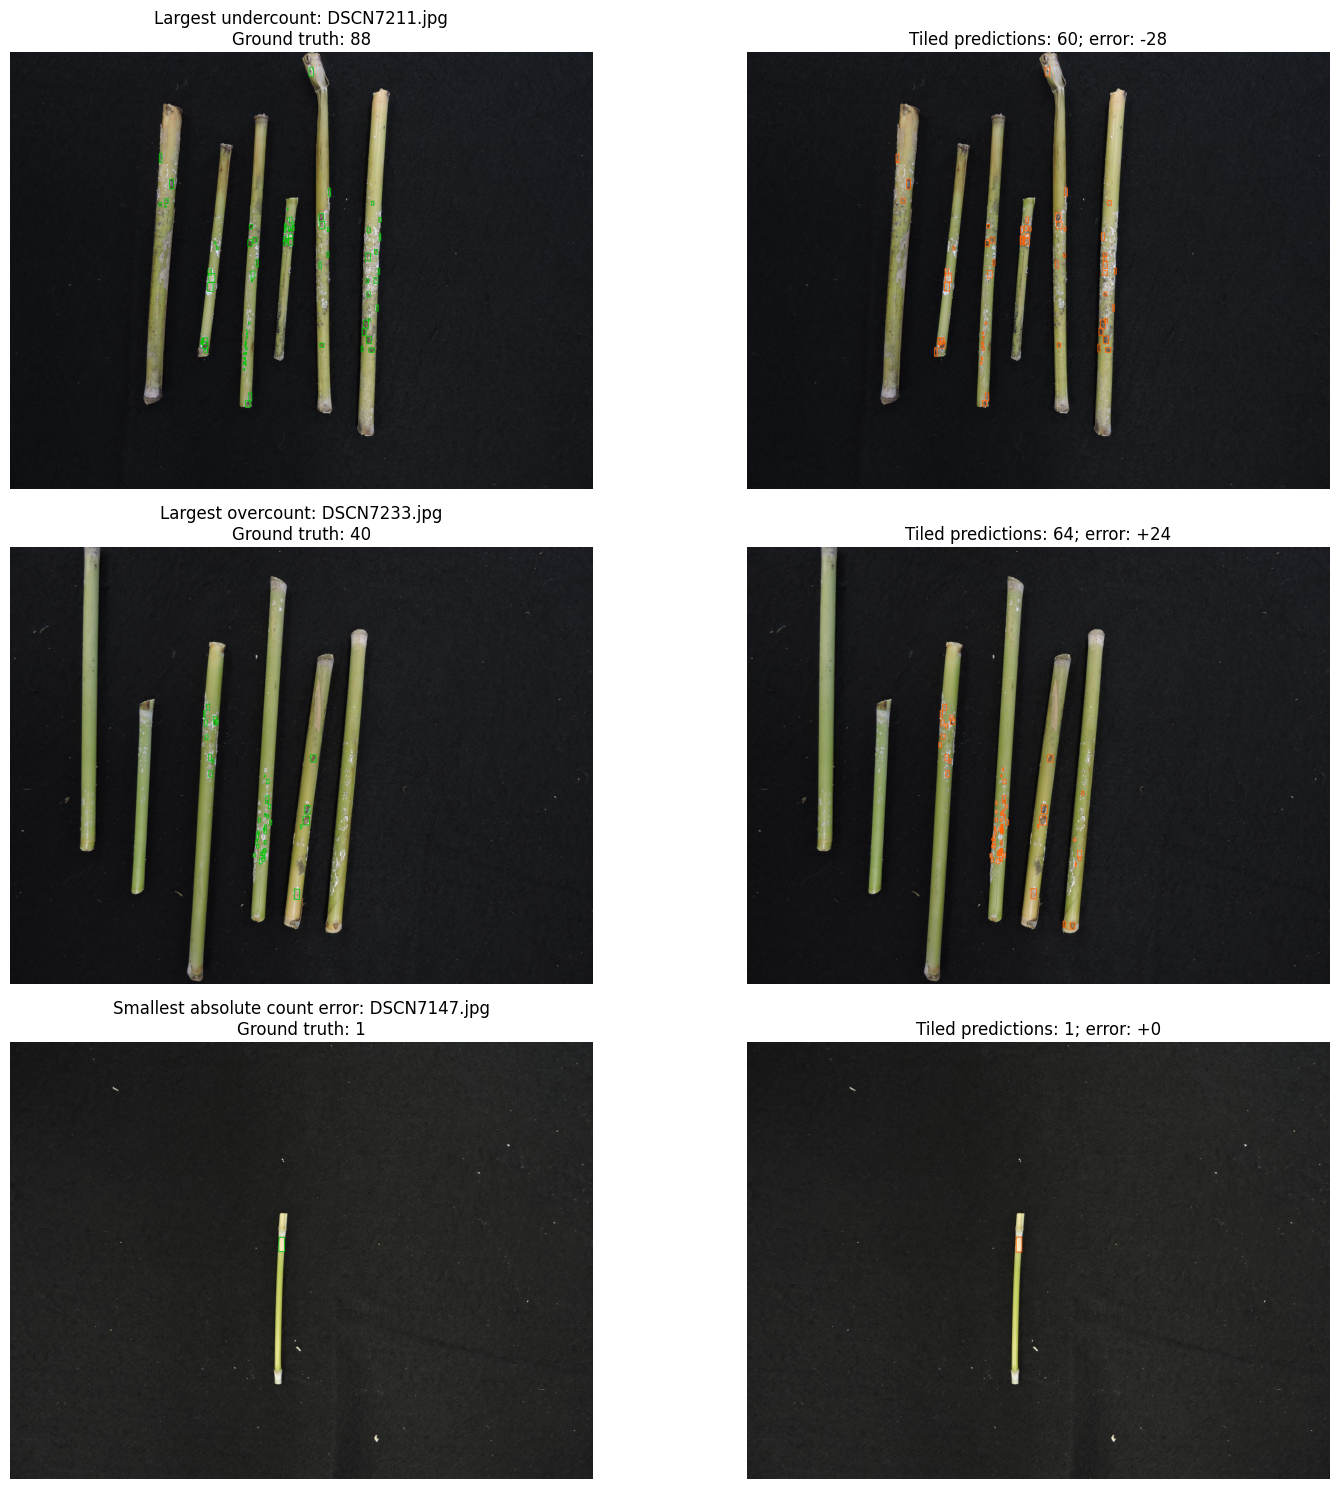

In [ ]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/roseau-scale-robustness/"
    "experiment/heldout_evaluation"
)
images_dir = Path("/content/roseau-scale/evaluation/full_test/images")
records = json.loads(
    (results_dir / "clean_predictions.json").read_text()
)

def count_error(record):
    predicted = sum(s >= 0.2 for s in record["tiled"]["scores"])
    return predicted - len(record["ground_truth_boxes"])

ordered = sorted(records, key=lambda r: r["image"])
examples = [
    ("Largest undercount", min(ordered, key=count_error)),
    ("Largest overcount", max(ordered, key=count_error)),
    ("Smallest absolute count error",
     min(ordered, key=lambda r: abs(count_error(r))))
]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))

for row, (description, record) in enumerate(examples):
    image = cv2.cvtColor(
        cv2.imread(str(images_dir / record["image"])),
        cv2.COLOR_BGR2RGB
    )
    gt_view = image.copy()
    prediction_view = image.copy()

    for box in record["ground_truth_boxes"]:
        x1, y1, x2, y2 = map(lambda v: int(round(v)), box)
        cv2.rectangle(gt_view, (x1, y1), (x2, y2), (0, 200, 0), 2)

    predicted = 0
    for box, score in zip(
        record["tiled"]["boxes"], record["tiled"]["scores"]
    ):
        if score >= 0.2:
            predicted += 1
            x1, y1, x2, y2 = map(lambda v: int(round(v)), box)
            cv2.rectangle(
                prediction_view, (x1, y1), (x2, y2), (255, 100, 0), 2
            )

    axes[row, 0].imshow(gt_view)
    axes[row, 0].set_title(
        f"{description}: {record['image']}\n"
        f"Ground truth: {len(record['ground_truth_boxes'])}"
    )
    axes[row, 1].imshow(prediction_view)
    axes[row, 1].set_title(
        f"Tiled predictions: {predicted}; error: {count_error(record):+d}"
    )
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

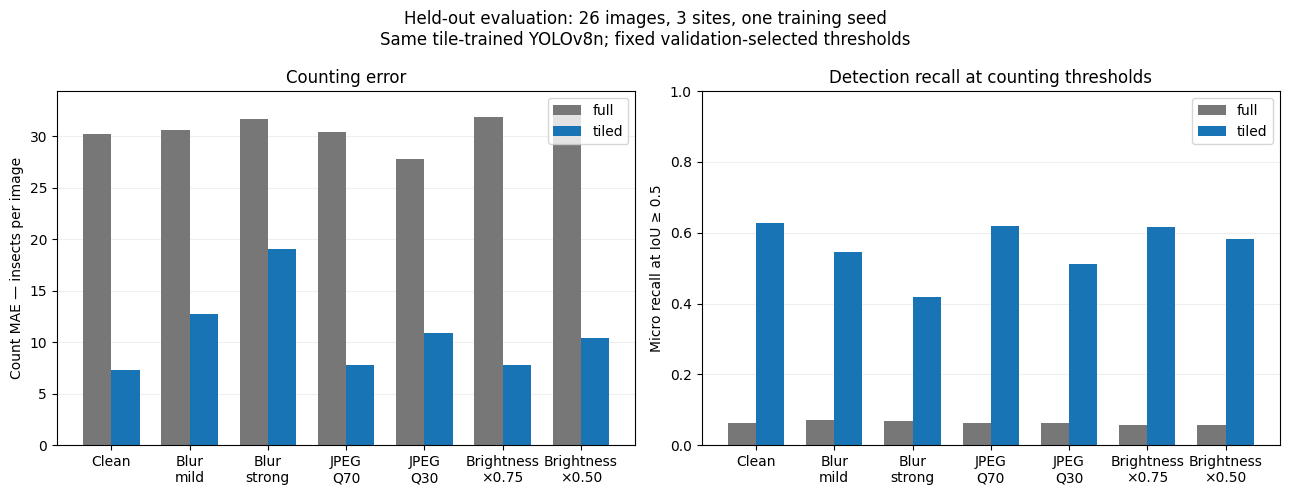

  condition method    MAE    bias  precision  recall    F1
  blur_mild   full 30.615 -30.538      0.228   0.070 0.108
  blur_mild  tiled 12.731 -12.269      0.755   0.545 0.633
blur_strong   full 31.654 -31.577      0.234   0.067 0.104
blur_strong  tiled 19.077 -19.000      0.733   0.418 0.533
      clean   full 30.192 -30.115      0.199   0.063 0.096
      clean  tiled  7.269  -3.731      0.686   0.628 0.655
  dark_mild   full 31.846 -31.769      0.204   0.057 0.090
  dark_mild  tiled  7.769  -5.308      0.699   0.615 0.654
dark_strong   full 32.731 -32.731      0.214   0.056 0.088
dark_strong  tiled 10.423  -8.962      0.730   0.582 0.647
  jpeg_mild   full 30.385 -30.308      0.199   0.063 0.095
  jpeg_mild  tiled  7.731  -4.115      0.683   0.619 0.649
jpeg_strong   full 27.769 -27.692      0.165   0.062 0.090
jpeg_strong  tiled 10.923  -9.308      0.646   0.510 0.570

Saved reports to: /content/drive/MyDrive/roseau-scale-robustness/reports


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

root = Path(
    "/content/drive/MyDrive/roseau-scale-robustness"
)
evaluation = root / "experiment/heldout_evaluation"
reports = root / "reports"
reports.mkdir(exist_ok=True)

df = pd.read_csv(evaluation / "per_image_metrics.csv")

# Verify one row per image, condition, method, and operating point.
keys = ["condition", "purpose", "method", "image"]
assert not df.duplicated(keys).any()
assert len(df) == 7 * 2 * 2 * 26

df["absolute_error"] = df["error"].abs()

summary = df.groupby(
    ["condition", "purpose", "method", "confidence"],
    as_index=False
).agg(
    images=("image", "count"),
    MAE=("absolute_error", "mean"),
    bias=("error", "mean"),
    TP=("TP", "sum"),
    FP=("FP", "sum"),
    FN=("FN", "sum")
)

summary["precision"] = (
    summary["TP"] / (summary["TP"] + summary["FP"]).clip(lower=1)
)
summary["recall"] = (
    summary["TP"] / (summary["TP"] + summary["FN"]).clip(lower=1)
)
summary["F1"] = (
    2 * summary["precision"] * summary["recall"]
    / (summary["precision"] + summary["recall"]).clip(lower=1e-12)
)
summary.to_csv(reports / "heldout_summary.csv", index=False)

order = [
    "clean", "blur_mild", "blur_strong", "jpeg_mild",
    "jpeg_strong", "dark_mild", "dark_strong"
]
labels = [
    "Clean", "Blur\nmild", "Blur\nstrong", "JPEG\nQ70",
    "JPEG\nQ30", "Brightness\n×0.75", "Brightness\n×0.50"
]

# Primary counting operating points: full=0.10, tiled=0.20.
counting = summary[summary["purpose"] == "counting"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(order))

for offset, method, color in [
    (-0.18, "full", "#777777"),
    (0.18, "tiled", "#1874B4")
]:
    values = counting[counting["method"] == method].set_index(
        "condition"
    ).loc[order]
    axes[0].bar(
        x + offset, values["MAE"], width=0.36,
        label=method, color=color
    )
    axes[1].bar(
        x + offset, values["recall"], width=0.36,
        label=method, color=color
    )

axes[0].set_ylabel("Count MAE — insects per image")
axes[0].set_title("Counting error")
axes[1].set_ylabel("Micro recall at IoU ≥ 0.5")
axes[1].set_title("Detection recall at counting thresholds")
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.set_xticks(x, labels)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Held-out evaluation: 26 images, 3 sites, one training seed\n"
    "Same tile-trained YOLOv8n; fixed validation-selected thresholds"
)
fig.tight_layout()
fig.savefig(reports / "robustness_results.png", dpi=200)
fig.savefig(reports / "robustness_results.pdf")
plt.show()

print(counting[
    ["condition", "method", "MAE", "bias", "precision", "recall", "F1"]
].round(3).to_string(index=False))
print("\nSaved reports to:", reports)